# Regresión logística para predecir el éxito de campañas de crowdfunding

Este notebook desarrolla un modelo de **regresión logística binaria múltiple** para estimar la probabilidad de que una campaña alcance su meta (`Success`). La base contiene 2.272 campañas de la Unión Europea.

> **Criterio metodológico:** la predicción debe utilizar únicamente información disponible antes o al inicio de la campaña. Por ello no se usan variables que reflejan el resultado final o el comportamiento posterior de los aportantes. La predicción es una asociación estadística y no una garantía de éxito.

## 1. Librerías y configuración

El código puede ejecutarse en Google Colab o en un entorno local.

In [12]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

## 2. Carga de la base

Si trabajas en Colab y la ruta local no existe, se habilita la carga manual del archivo `eu_limpio.csv`.

In [2]:
RUTA_CSV = 'eu_limpio.csv'

try:
    df = pd.read_csv(RUTA_CSV)
except FileNotFoundError:
    from google.colab import files
    archivos = files.upload()
    nombre = next(iter(archivos))
    df = pd.read_csv(nombre)

print('Dimensiones:', df.shape)
display(df.head())
df.info()

Saving eu_limpio.csv to eu_limpio (1).csv
Dimensiones: (2272, 223)


,ID,Start_Date,End_Date,Duration,Category,Category_Kickstarter,Success,Funding,Funding_IHS,Target,...,Flag_IQR_Duration_Calendar,Flag_IQR_Description,Flag_IQR_Rewards,Flag_IQR_Prev_Success,Flag_IQR_Backed,Flag_IQR_Links,Category_Creative_Arts,Category_Design,Category_Literature_Journalism,Category_Food
0,4,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,2461.23,8.501564,1085.20,...,0,0,0,0,0,0,0,0,0,0
1,7,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,37601.09,11.227935,2170.40,...,0,0,0,0,1,0,0,0,0,0
2,12,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,4531.80,9.112022,732.51,...,0,0,0,0,1,0,0,0,0,0
3,16,2022-02-17,2022-03-07,17,Media & Entertainment,games,1,18787.60,10.534100,5000.00,...,0,0,0,1,0,0,0,0,0,0
4,17,2022-02-04,2022-03-07,31,Media & Entertainment,film & video,0,1451.00,7.973156,3198.00,...,0,0,0,0,0,0,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2272 entries, 0 to 2271
Columns: 223 entries, ID to Category_Food
dtypes: float64(15), int64(201), object(7)
memory usage: 3.9+ MB


## 3. Diagnóstico inicial y variable objetivo

Valores faltantes por variable:


,Nulos
Adjacent_Ctry_Share_Clean,32
Same_Ctry_Share_Clean,32
ID,0
Duration,0
Category,0
Start_Date,0
End_Date,0
Funding,0
Funding_IHS,0
Target,0


Duplicados: 0
Distribución de Success:


,Frecuencia
Success,
Éxito,1855
No éxito,417


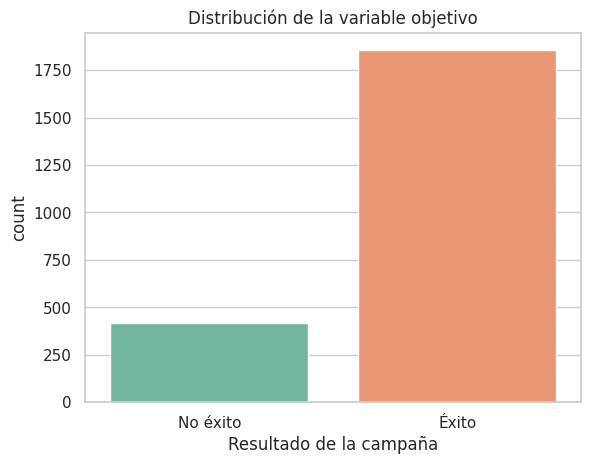

In [3]:
print('Valores faltantes por variable:')
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame('Nulos'))
print('Duplicados:', df.duplicated().sum())
print('Distribución de Success:')
display(df['Success'].value_counts().rename(index={0: 'No éxito', 1: 'Éxito'}).to_frame('Frecuencia'))

ax = sns.countplot(data=df, x='Success', hue='Success', legend=False, palette='Set2')
ax.set_xticks([0, 1], ['No éxito', 'Éxito'])
ax.set_title('Distribución de la variable objetivo')
ax.set_xlabel('Resultado de la campaña')
plt.show()

## 4. Variables incluidas en el modelo

El modelo usa **únicamente** las 11 variables definidas para el análisis: categoría, meta, duración, recursos audiovisuales, longitud de descripción, recompensas, éxitos previos, campañas respaldadas y enlaces.

No se incorporan las demás columnas de la base. En particular, `Funding` se mantiene fuera porque refleja el financiamiento alcanzado, que está directamente relacionado con el resultado final.

In [4]:
TARGET = 'Success'
FEATURES = [
    'Category', 'Target', 'Duration', 'Video_Header', 'Videos_Bool',
    'Images_Bool', 'Description', 'Rewards', 'Prev_Success', 'Backed', 'Links'
]

faltantes_features = [c for c in FEATURES if c not in df.columns]
if faltantes_features:
    raise ValueError(f'Faltan columnas esperadas: {faltantes_features}')

X = df[FEATURES].copy()
y = df[TARGET].astype(int)
print('Predictores utilizados:', len(FEATURES), '(solo las variables solicitadas)')
print(FEATURES)
print('Proporción de éxito:', round(y.mean(), 4))

Predictores utilizados: 11 (solo las variables solicitadas)
['Category', 'Target', 'Duration', 'Video_Header', 'Videos_Bool', 'Images_Bool', 'Description', 'Rewards', 'Prev_Success', 'Backed', 'Links']
Proporción de éxito: 0.8165


## 5. División estratificada y preprocesamiento

La prueba se reserva para la evaluación final. La imputación, estandarización y codificación se realizan dentro de un `Pipeline`, evitando que el conjunto de prueba influya en el entrenamiento.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocesador = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Numéricas:', num_cols)
print('Categóricas:', cat_cols)

Entrenamiento: (1590, 11) | Prueba: (682, 11)
Numéricas: ['Target', 'Duration', 'Video_Header', 'Videos_Bool', 'Images_Bool', 'Description', 'Rewards', 'Prev_Success', 'Backed', 'Links']
Categóricas: ['Category']


## 6. Entrenamiento y selección del modelo

Se prueban distintos valores de regularización `C` y dos opciones para el desbalance de clases. La selección se hace con ROC-AUC mediante validación cruzada estratificada.

In [6]:
pipeline_logit = Pipeline(steps=[
    ('preprocesamiento', preprocesador),
    ('modelo', LogisticRegression(max_iter=2000, solver='liblinear', random_state=RANDOM_STATE))
])

parametros = {
    'modelo__C': [0.01, 0.1, 1, 10, 100],
    'modelo__class_weight': [None, 'balanced']
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
busqueda = GridSearchCV(pipeline_logit, parametros, cv=cv, scoring='roc_auc',
                       n_jobs=-1, return_train_score=True)
busqueda.fit(X_train, y_train)

modelo = busqueda.best_estimator_
print('Mejores parámetros:', busqueda.best_params_)
print('ROC-AUC promedio en validación cruzada:', round(busqueda.best_score_, 4))

Mejores parámetros: {'modelo__C': 1, 'modelo__class_weight': None}
ROC-AUC promedio en validación cruzada: 0.7915


## 7. Evaluación en el conjunto de prueba

In [7]:
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

metricas = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC'],
    'Valor': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob)
    ]
})
display(metricas.round(4))
print(classification_report(y_test, y_pred, target_names=['No éxito', 'Éxito'], zero_division=0))

,Métrica,Valor
0,Accuracy,0.8416
1,Precision,0.8481
2,Recall,0.9820
3,F1,0.9101
4,ROC-AUC,0.8209
5,PR-AUC,0.9509


              precision    recall  f1-score   support

    No éxito       0.73      0.22      0.33       125
       Éxito       0.85      0.98      0.91       557

    accuracy                           0.84       682
   macro avg       0.79      0.60      0.62       682
weighted avg       0.83      0.84      0.80       682



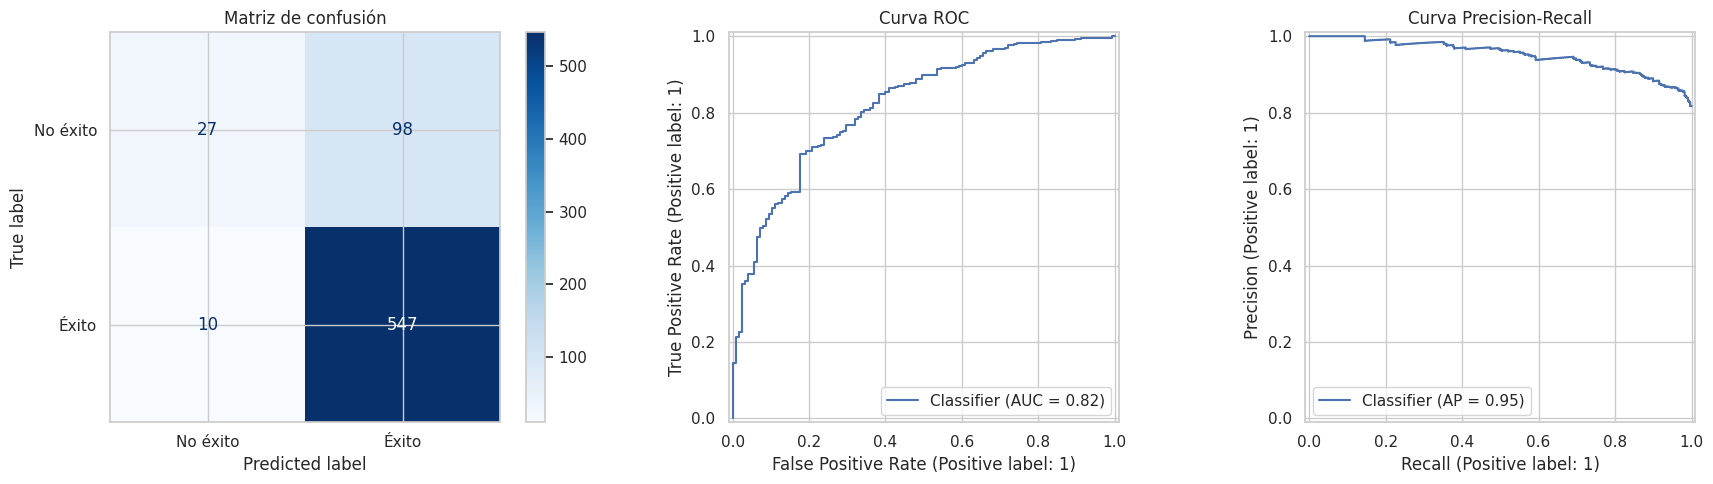

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No éxito', 'Éxito'], cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de confusión')
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title('Curva ROC')
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2])
axes[2].set_title('Curva Precision-Recall')
plt.tight_layout()
plt.show()

## 8. Interpretación de coeficientes y odds ratios

En las variables numéricas estandarizadas, un coeficiente positivo aumenta la probabilidad estimada de éxito y uno negativo la reduce, manteniendo constantes las demás variables. El `odds ratio` es `exp(coeficiente)`: valores mayores que 1 indican aumento de las odds y valores menores que 1 indican disminución. La interpretación no implica causalidad.

,Variable,Coeficiente,Odds_Ratio,Abs_Coeficiente
0,num__Target,-2.0611,0.1273,2.0611
7,num__Prev_Success,1.3169,3.7319,1.3169
10,cat__Category_Creative Arts,0.7584,2.1348,0.7584
14,cat__Category_Media & Entertainment,0.3683,1.4453,0.3683
6,num__Rewards,0.3433,1.4096,0.3433
1,num__Duration,-0.2776,0.7576,0.2776
11,cat__Category_Design,0.2400,1.2712,0.2400
13,cat__Category_Literature & Journalism,0.2074,1.2305,0.2074
3,num__Videos_Bool,-0.1485,0.8620,0.1485
9,num__Links,0.1254,1.1336,0.1254


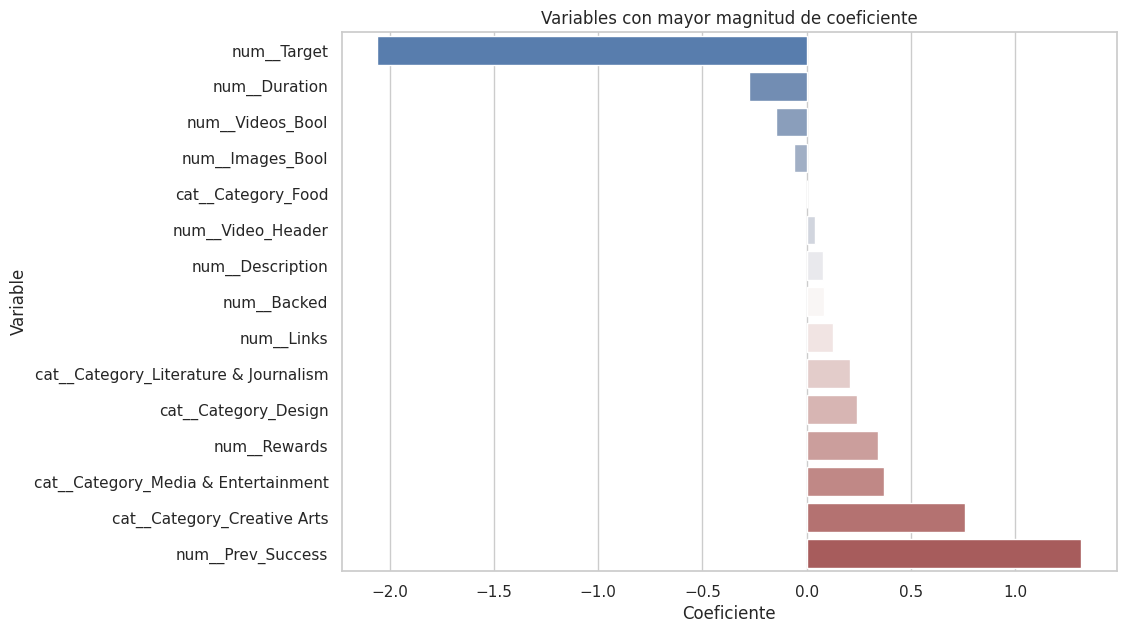

In [9]:
preprocesador_ajustado = modelo.named_steps['preprocesamiento']
logit = modelo.named_steps['modelo']
nombres = preprocesador_ajustado.get_feature_names_out()
tabla_coef = pd.DataFrame({
    'Variable': nombres,
    'Coeficiente': logit.coef_[0]
})
tabla_coef['Odds_Ratio'] = np.exp(tabla_coef['Coeficiente'])
tabla_coef['Abs_Coeficiente'] = tabla_coef['Coeficiente'].abs()
tabla_coef = tabla_coef.sort_values('Abs_Coeficiente', ascending=False)
display(tabla_coef.head(20).round(4))

plt.figure(figsize=(10, 7))
top = tabla_coef.head(15).sort_values('Coeficiente')
sns.barplot(data=top, x='Coeficiente', y='Variable', hue='Variable', legend=False, palette='vlag')
plt.title('Variables con mayor magnitud de coeficiente')
plt.show()

## 9. Predicción de una nueva campaña

El ejemplo toma una observación del conjunto de prueba. Para una aplicación real, reemplaza `nueva_campaña` por un `DataFrame` con las columnas de `FEATURES`.

In [10]:
nueva_campaña = X_test.iloc[[0]].copy()
probabilidad_exito = modelo.predict_proba(nueva_campaña)[0, 1]
prediccion = int(probabilidad_exito >= 0.50)

print('Predicción:', 'Éxito' if prediccion == 1 else 'No éxito')
print(f'Probabilidad estimada de éxito: {probabilidad_exito:.2%}')
display(nueva_campaña)

Predicción: Éxito
Probabilidad estimada de éxito: 71.18%


,Category,Target,Duration,Video_Header,Videos_Bool,Images_Bool,Description,Rewards,Prev_Success,Backed,Links
133,Media & Entertainment,53.97,30,0,1,1,10,6,0,2,0


## 10. Conclusiones y limitaciones para el informe

- La métrica principal debe complementarse con recall, F1, ROC-AUC y PR-AUC; la clase `Success=1` es mayoritaria (aproximadamente 81,65%).
- Los coeficientes muestran asociaciones condicionadas al resto de variables, no efectos causales.
- El modelo predice patrones históricos de campañas de la Unión Europea y puede perder desempeño en otros periodos, países o categorías.
- Antes de usarlo operativamente conviene validar nuevas campañas, revisar calibración de probabilidades, controlar la fuga de información y comparar distintos umbrales de decisión.
- No se deben interpretar las predicciones como garantías de financiación.

## 12. Evaluación mediante validación cruzada

Generamos predicciones de validación con un umbral de 0,50 y calculamos las mismas métricas que en Random Forest. Estos resultados son orientativos porque reutilizamos las particiones empleadas para ajustar los parámetros. No utilizamos el conjunto de prueba.

In [13]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score

probabilidades_cv = cross_val_predict(
    clone(modelo),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

predicciones_cv = (probabilidades_cv >= 0.50).astype(int)

print(classification_report(
    y_train,
    predicciones_cv,
    labels=[0, 1],
    target_names=["No exitosa", "Exitosa"],
    digits=3,
    zero_division=0
))

resumen_logit = pd.DataFrame([{
    "Modelo": "Regresión logística",
    "ROC_AUC_CV": busqueda.best_score_,
    "Exactitud_CV": accuracy_score(y_train, predicciones_cv),
    "Exactitud_balanceada_CV": balanced_accuracy_score(
        y_train, predicciones_cv
    ),
    "Precision_no_exitosa_CV": precision_score(
        y_train, predicciones_cv,
        pos_label=0, zero_division=0
    ),
    "Recall_no_exitosa_CV": recall_score(
        y_train, predicciones_cv,
        pos_label=0, zero_division=0
    ),
    "F1_macro_CV": f1_score(
        y_train, predicciones_cv,
        average="macro", zero_division=0
    )
}])

display(resumen_logit.round(4))

              precision    recall  f1-score   support

  No exitosa      0.725     0.199     0.312       292
     Exitosa      0.845     0.983     0.909      1298

    accuracy                          0.839      1590
   macro avg      0.785     0.591     0.610      1590
weighted avg      0.823     0.839     0.799      1590



,Modelo,ROC_AUC_CV,Exactitud_CV,Exactitud_balanceada_CV,Precision_no_exitosa_CV,Recall_no_exitosa_CV,F1_macro_CV
0,Regresión logística,0.7915,0.839,0.5908,0.725,0.1986,0.6103


## 13. Guardar el modelo entrenado (opcional)

El archivo permite reutilizar el pipeline completo, incluyendo imputación, escalamiento, codificación y regresión logística.

In [11]:
import joblib
joblib.dump({'modelo': modelo, 'features': FEATURES}, 'modelo_regresion_logistica_crowdfunding.joblib')
print('Modelo guardado correctamente.')

Modelo guardado correctamente.
